## Trabajo práctico — Redes neuronales con NumPy y PyTorch

### Preparación
[Presentación de clase](https://docs.google.com/presentation/d/1mdyWXUdixJ9UHNxtIBKhRFODpSTmfAogFm1QsRVEcdw/edit?usp=sharing)

La primera vez puede ser necesario instalar `torch`, `torchvision`. En Colab suelen estar disponibles. Ejecutá esta celda para verificar el entorno.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print('PyTorch:', torch.__version__)
print('Dispositivo: CPU')

PyTorch: 2.15.0+cpu
Dispositivo: CPU


### 1. Perceptrón simple clásico: cálculo e implementación

### Actividad 1 — Actualización manual de los pesos

Un perceptrón tiene $x_0=1$,

dos entradas $\mathbf{x}=(1{,}5;-0{,}8)$,

pesos $\mathbf{w} = (w_0, w_1, w_2) =(0{,}2;0{,}4;-0{,}3)$,

etiqueta real $y=-1$ y tasa de aprendizaje $\eta=0{,}1$.

Calculá **a mano**:

los tres pesos nuevos actualizados. Explicá por qué se actualizan o no los pesos.

### Actividad 2 — Regla del perceptrón con NumPy

Se trabajará inicialmente con dos especies de Iris (**setosa** y **versicolor**) y dos características: largo de sépalo y largo de pétalo. Las clases se codifican como **−1** y **+1**, respectivamente.

**Consignas:**

- Identificá en la clase `Perceptron` los métodos que realizan la suma ponderada, la predicción y el ajuste de los pesos.
- Completá las líneas señaladas como `TODO` y entrená el modelo.
- Representá e interpretá **tres gráficos**:

    (1) cantidad de patrones mal clasificados por época,

    (2) error individual `e = y - y_pred` registrado para cada patrón presentado durante el entrenamiento y

    (3) datos de Iris junto con la frontera de decisión obtenida.

- Probá distintos valores de `eta` y `epocas`, y analizá cómo cambian los resultados.

**Importante:**

Estos tres gráficos deberán realizarse **en los dos experimentos** de la actividad: *setosa frente a versicolor* y *versicolor frente a virginica*.

**Recordatorio:**

El error de un patrón es $e=y-\hat y$. Con las etiquetas −1/+1 puede tomar los valores −2, 0 y +2. Ese error individual no es lo mismo que la cantidad de patrones mal clasificados por época. Esta distinción es necesaria para interpretar los gráficos.

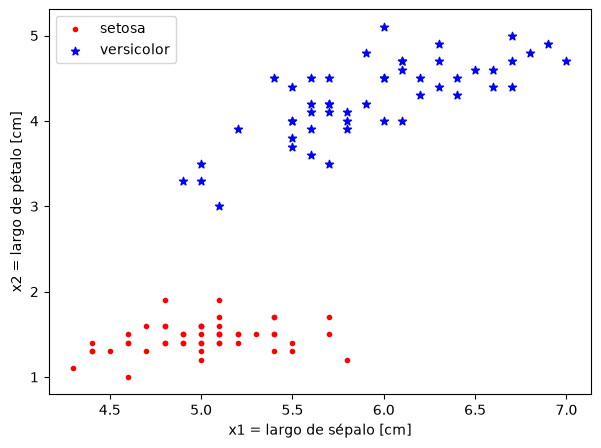

In [42]:
iris = load_iris()

# Primera y tercera características: largo de sépalo y largo de pétalo.
X_np = iris.data[:100, [0, 2]].astype(float)
y = np.where(iris.target[:100] == 0, -1, 1)  # -1: setosa; +1: versicolor
y_pm = y  # Se mantiene este nombre para las celdas posteriores.

plt.figure(figsize=(7, 5))
plt.scatter(X_np[:50, 0], X_np[:50, 1], color="red", marker=".", label="setosa")
plt.scatter(X_np[50:, 0], X_np[50:, 1], color="blue", marker="*", label="versicolor")
plt.xlabel("x1 = largo de sépalo [cm]")
plt.ylabel("x2 = largo de pétalo [cm]")
plt.legend()
plt.show()

In [43]:
from numpy.random import RandomState

class Perceptron(object):
    """Perceptrón simple con la estructura de la notebook original.

    eta: tasa de aprendizaje.
    epocas: cantidad de épocas de entrenamiento.
    random_state: semilla para inicializar los pesos.
    """
    def __init__(self, eta=0.001, epocas=1, random_state=None):
        self.eta = eta
        self.epocas = epocas
        self.random_state = random_state

    def fit(self, X, y):
        """Entrena el perceptrón con la regla de corrección del error."""
        generador = RandomState(self.random_state)
        self.w_ = generador.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.mal_clasificados_ = []
        self.errores_ = []

        X = np.insert(X, 0, 1, axis=1)  # Incorporar x0 = 1 (sesgo).

        for _ in range(self.epocas):
            mal_clasificados = 0
            for xi, target in zip(X, y):
                y_pred = self.predict(xi)

                # TODO: identificar el cálculo del error y la actualización.
                # ----------------------------------------------------------------
                error = target - y_pred           # e = y - ysombrerito  (puede ser -2, 0 o +2)
                self.w_ += self.eta * error * xi  # Regla del perceptrón: Δw = n·e·x
                self.errores_.append(error)       # se guarda el error de cada patrón presentado
                mal_clasificados += int(error != 0)  # dice si este patrón fue un error
                # -----------------------

            self.mal_clasificados_.append(mal_clasificados)  # se guarda el total de la época


            # ----------------------------------------------------------------
        return self

    def calcular_entrada(self, x):
        """Calcula la suma ponderada, incluido el sesgo."""
        # TODO: relacionar esta operación con la expresión matemática.
        """Suma ponderada: z = w0 + w1*x1 + ... + wN*xN."""
        # ----------------------------------------------------------------
        # Como x ya trae x0 = 1, el producto punto incluye el sesgo
        return np.dot(x, self.w_)
        # ----------------------------------------------------------------

    def predict(self, X):
        """Devuelve la clase -1 o +1 aplicando la función umbral."""
        # TODO: identificar el umbral y sus dos posibles salidas.
        # ----------------------------------------------------------------
        """Función umbral: +1 si z >= 0, -1 si z < 0."""
        return np.where(self.calcular_entrada(X) >= 0.0, 1, -1)
        # ----------------------------------------------------------------

**Identificación de los métodos de `Perceptron`.**

- **Suma ponderada:** `calcular_entrada`. Calcula $z = w_0 + w_1x_1 + \dots + w_Nx_N = \mathbf{w}^T\mathbf{x}$ con `np.dot(x, self.w_)`; como a cada patrón se le agrega $x_0=1$, el producto punto incluye el sesgo $w_0$.
- **Predicción:** `predict`. Aplica la función umbral a $z$: devuelve $+1$ si $z \ge 0$ y $-1$ si $z<0$.
- **Ajuste de los pesos:** `fit`. Recorre los patrones de a uno; para cada uno calcula el error $e=y-\hat y$ y actualiza $\mathbf{w} \leftarrow \mathbf{w} + \eta\, e\, \mathbf{x}$ (regla del perceptrón). Si $e=0$, los pesos no cambian.

Pesos finales [w0, w1, w2]: [-0.02375655 -0.07011756  0.17671828]


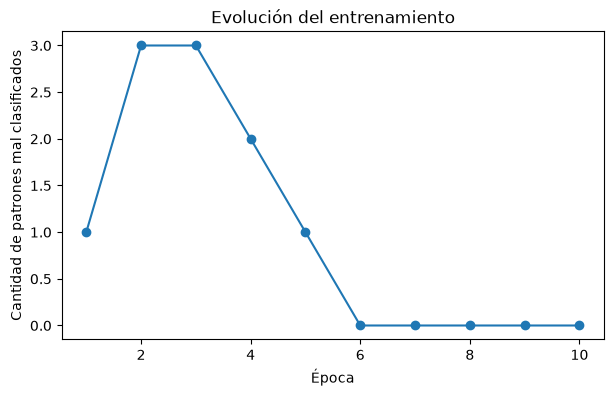

In [44]:
# --------------Entrenar el modelo   --------------------------
perceptron = Perceptron(eta=0.01, epocas=10, random_state=1)
perceptron.fit(X_np, y)
print("Pesos finales [w0, w1, w2]:", perceptron.w_)
# ----------------------------------------------------------------

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(perceptron.mal_clasificados_) + 1),
         perceptron.mal_clasificados_, marker="o")
plt.xlabel("Época")
plt.ylabel("Cantidad de patrones mal clasificados")
plt.title("Evolución del entrenamiento")
plt.show()

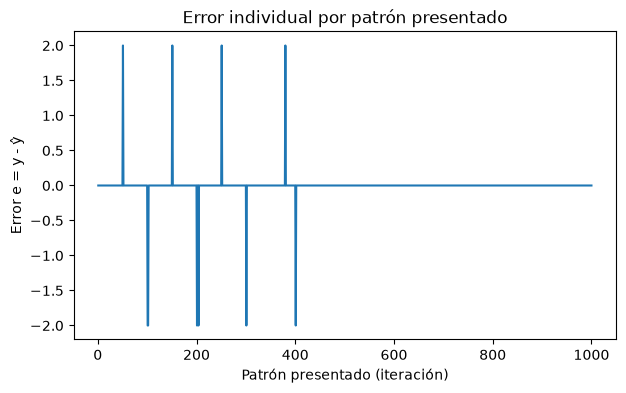

In [45]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(perceptron.errores_) + 1),
         perceptron.errores_)
plt.xlabel("Patrón presentado (iteración)")
plt.ylabel("Error e = y - ŷ")
plt.title("Error individual por patrón presentado")
plt.show()

### Frontera de decisión del perceptrón simple

Recordemos la ecuación de la salida del perceptrón:

$$
\hat y=\operatorname{sign}\left(w_0+\sum_{i=1}^{N}x_iw_i\right).
$$

Para este problema, con dos características ($x_1$: largo de sépalo; $x_2$: largo de pétalo), resulta:

$$
\hat y=\operatorname{sign}(x_1w_1+x_2w_2+w_0).
$$

La **frontera de decisión** corresponde a los puntos donde la entrada neta es cero:

$$
x_1w_1+x_2w_2+w_0=0.
$$

Despejando $x_2$ en función de $x_1$:

$$
x_2+x_1\frac{w_1}{w_2}+\frac{w_0}{w_2}=0,
$$

$$
\boxed{x_2=-\frac{w_1}{w_2}x_1-\frac{w_0}{w_2}}.
$$

Comparando con la ecuación de una recta $x_2=mx_1+b$, obtenemos:

$$
\boxed{m=-\frac{w_1}{w_2}},\qquad
\boxed{b=-\frac{w_0}{w_2}}.
$$

Por lo tanto, a partir de los pesos aprendidos podemos calcular la **pendiente** $m$ y la **ordenada al origen** $b$, y representar la recta junto con las dos clases.

**Consigna:** utilizá estas expresiones para construir e interpretar el gráfico de la frontera de decisión del perceptrón entrenado.


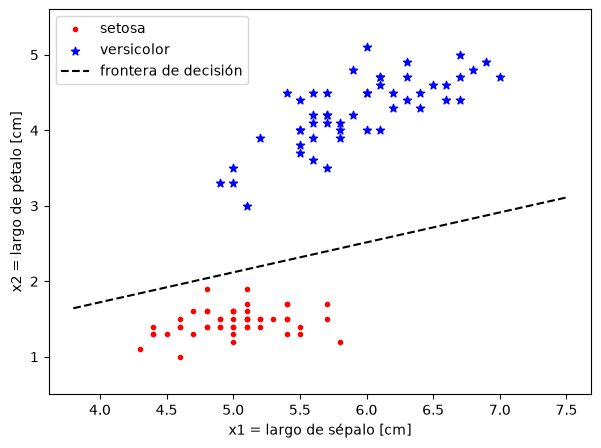

In [46]:
# Representación de la recta de separación con los datos.
# ----------------------------------------------------------------
# frontera de decisión
w0, w1, w2 = perceptron.w_  # sesgo y pesos aprendidos
m = -w1 / w2   # pendiente de la recta
b = -w0 / w2   # ordenada al origen

x1_rango = np.linspace(X_np[:, 0].min() - 0.5, X_np[:, 0].max() + 0.5, 100)
x2_frontera = m * x1_rango + b  # x2 = m*x1 + b

plt.figure(figsize=(7, 5))
plt.scatter(X_np[:50, 0], X_np[:50, 1], color="red", marker=".", label="setosa")
plt.scatter(X_np[50:, 0], X_np[50:, 1], color="blue", marker="*", label="versicolor")
plt.plot(x1_rango, x2_frontera, "k--", label="frontera de decisión")
plt.ylim(X_np[:, 1].min() - 0.5, X_np[:, 1].max() + 0.5)  # evita que la recta estire el eje Y
plt.xlabel("x1 = largo de sépalo [cm]")
plt.ylabel("x2 = largo de pétalo [cm]")
plt.legend()
plt.show()
# ----------------------------------------------------------------

**Para analizar (en ambos experimentos):** observá la cantidad de patrones mal clasificados por época y la secuencia de errores individuales. ¿Qué diferencias encontrás entre ambos gráficos? ¿Cómo se relacionan con la frontera de decisión? ¿Qué ocurre al modificar `eta` o la cantidad de épocas?

**Conclusiones — experimento 1 (setosa vs versicolor).**

- **Gráfico 1 (mal clasificados por época):** la cantidad fue 1, 3, 3, 2, 1 y llegó a **0 en la época 6**, donde se mantiene. El perceptrón **converge** porque setosa y versicolor son **linealmente separables** con estas dos características.
- **Gráfico 2 (error individual):** los errores aparecen solo durante las primeras ~5 épocas (hasta alrededor de la presentación 400) y valen $+2$ o $-2$. $+2$ significa que el patrón era $+1$ (versicolor) y se predijo $-1$, $-2$ significa lo contrario. Después todos los errores valen 0.
- **Diferencia entre ambos gráficos:** el gráfico 1 resume cuántos patrones fallaron en cada época; el gráfico 2 muestra cada error individual, con su signo, en el orden en que se presentaron los patrones.
- **Relación con la frontera:** cuando $e=0$ en todos los patrones, $\Delta w=0$ y los pesos dejan de cambiar. La recta final ($w=[-0{,}024;\,-0{,}070;\,0{,}177]$, o sea $m\approx0{,}40$ y $b\approx0{,}13$) separa las 100 flores sin errores.

**Segundo experimento — versicolor y virginica.**

Repetí el entrenamiento utilizando estas dos especies y las mismas características (largo de sépalo y largo de pétalo). Conservá la codificación −1/+1 y realizá nuevamente los **tres gráficos**: cantidad de patrones mal clasificados por época, errores individuales de los patrones presentados y frontera de decisión junto con los datos. Compará los resultados con los obtenidos para *setosa* y *versicolor*.

eta=0.01, épocas=10 -> pesos [w0,w1,w2] = [ 0.01624345 -0.12611756  0.24671828]
Mal clasificados en la última época: 2


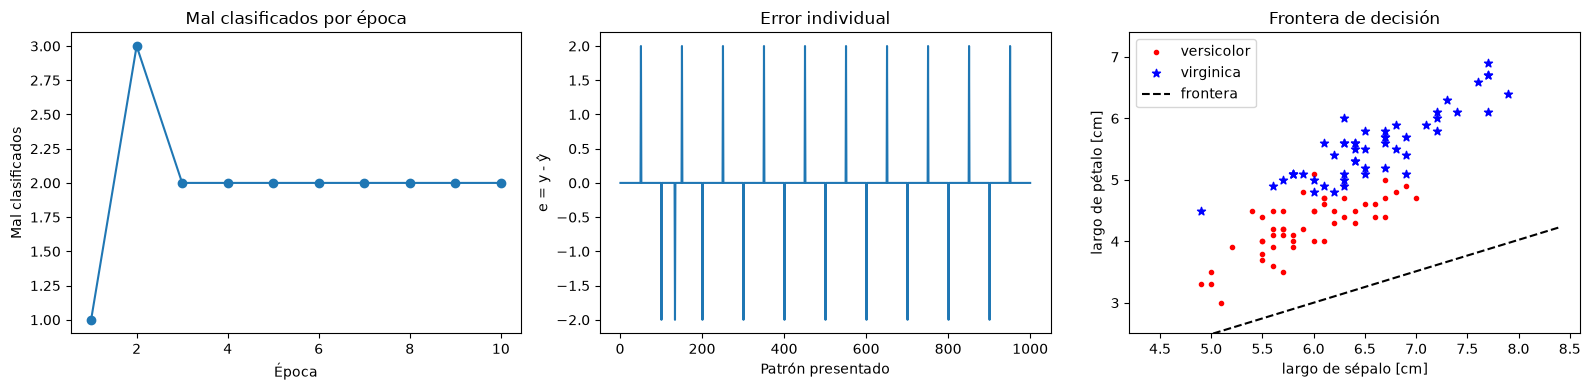

In [47]:
# Repetir el experimento con Iris versicolor (-1) e Iris virginica (+1).
# Utilizamos las mismas características: largo de sépalo y largo de pétalo.
X2 = iris.data[50:150, [0, 2]].astype(float)
y2 = np.where(iris.target[50:150] == 1, -1, 1)   # -1: versicolor, +1: virginica

def entrenar_y_graficar(X, y, eta, epocas, nombre_neg, nombre_pos):
    p = Perceptron(eta=eta, epocas=epocas, random_state=1).fit(X, y)
    print(f"eta={eta}, épocas={epocas} -> pesos [w0,w1,w2] = {p.w_}")
    print("Mal clasificados en la última época:", p.mal_clasificados_[-1])

    fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

    # Gráfico 1: patrones mal clasificados por época
    ejes[0].plot(range(1, epocas + 1), p.mal_clasificados_, marker="o")
    ejes[0].set_xlabel("Época"); ejes[0].set_ylabel("Mal clasificados")
    ejes[0].set_title("Mal clasificados por época")

    # Gráfico 2: error individual de cada patrón presentado
    ejes[1].plot(range(1, len(p.errores_) + 1), p.errores_)
    ejes[1].set_xlabel("Patrón presentado"); ejes[1].set_ylabel("e = y - ŷ")
    ejes[1].set_title("Error individual")

    # Gráfico 3: datos + frontera (x2 = m*x1 + b)
    w0, w1, w2 = p.w_
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
    ejes[2].scatter(X[y == -1, 0], X[y == -1, 1], color="red", marker=".", label=nombre_neg)
    ejes[2].scatter(X[y == 1, 0], X[y == 1, 1], color="blue", marker="*", label=nombre_pos)
    ejes[2].plot(x1, (-w1 / w2) * x1 - w0 / w2, "k--", label="frontera")
    ejes[2].set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    ejes[2].set_xlabel("largo de sépalo [cm]"); ejes[2].set_ylabel("largo de pétalo [cm]")
    ejes[2].set_title("Frontera de decisión"); ejes[2].legend()
    plt.tight_layout(); plt.show()
    return p

p2 = entrenar_y_graficar(X2, y2, eta=0.01, epocas=10, nombre_neg="versicolor", nombre_pos="virginica")

In [74]:
# Prueba de distintos valores de eta y épocas en ambos experimentos
for nombre, X_, y_ in [("setosa vs versicolor", X_np, y), ("versicolor vs virginica", X2, y2)]:
    print(nombre)
    for eta in [0.001, 0.01, 0.1]:
        for epocas in [5, 10, 50]:
            p = Perceptron(eta=eta, epocas=epocas, random_state=1).fit(X_, y_)
            # Errores reales de la recta FINAL sobre los 100 patrones (no durante el entrenamiento)
            mal_finales = (p.predict(np.insert(X_, 0, 1, axis=1)) != y_).sum()
            print(f"  eta={eta:<6} épocas={epocas:<3} mal en la última época={p.mal_clasificados_[-1]}  mal con pesos finales={mal_finales}")

setosa vs versicolor
  eta=0.001  épocas=5   mal en la última época=1  mal con pesos finales=0
  eta=0.001  épocas=10  mal en la última época=0  mal con pesos finales=0
  eta=0.001  épocas=50  mal en la última época=0  mal con pesos finales=0
  eta=0.01   épocas=5   mal en la última época=1  mal con pesos finales=0
  eta=0.01   épocas=10  mal en la última época=0  mal con pesos finales=0
  eta=0.01   épocas=50  mal en la última época=0  mal con pesos finales=0
  eta=0.1    épocas=5   mal en la última época=1  mal con pesos finales=0
  eta=0.1    épocas=10  mal en la última época=0  mal con pesos finales=0
  eta=0.1    épocas=50  mal en la última época=0  mal con pesos finales=0
versicolor vs virginica
  eta=0.001  épocas=5   mal en la última época=2  mal con pesos finales=50
  eta=0.001  épocas=10  mal en la última época=2  mal con pesos finales=50
  eta=0.001  épocas=50  mal en la última época=2  mal con pesos finales=29
  eta=0.01   épocas=5   mal en la última época=2  mal con pesos 

**Conclusiones — experimento 2 (versicolor vs virginica) y efecto de `eta` y las épocas.**

- **Gráfico 1:** la cantidad de mal clasificados fue 1, 3, 2, 2, 2... y **nunca llega a 0**: queda en 2 por época.
- **Gráfico 2:** los errores ($+2$ y $-2$) se repiten **en cada época** hasta el final del entrenamiento. Son siempre los mismos dos patrones: el primer versicolor (error $-2$) y el primer virginica (error $+2$).
- **Frontera:** la recta graficada queda por debajo de todos los puntos y clasifica los 100 patrones como virginica (50 errores reales). Los "2 errores por época" se cuentan mientras los pesos van cambiando; la recta final es solo la recta del último instante. Como los pesos oscilan, cuál recta queda depende de en qué punto se detiene el entrenamiento.
- **Por qué no converge:** versicolor y virginica **se superponen** en largo de sépalo y de pétalo (por ejemplo, hay un virginica en la zona de versicolor), así que no existe una recta que los separe. Cuando las clases no son linealmente separables, el perceptrón no deja de corregir pesos.
- **Comparación:** en el experimento 1 el perceptrón converge y la recta separa todo; en el 2 oscila indefinidamente y no logra una solución.
- **Efecto de `eta` y de las épocas (ver tabla de pruebas):** en el experimento 1, con 5 épocas todavía queda un error, pero con 10 o más épocas se llega a 0 errores para los tres valores de `eta`, aunque la recta final cambia (con `eta` = 0,001 la recta es bastante distinta de las de 0,01 y 0,1, y todas separan bien). En el experimento 2, ni cambiar `eta` ni aumentar las épocas resuelve el problema, porque el límite es la separabilidad de los datos y no la configuración. 

En la siguiente sección volveremos a usar los mismos datos, pero **ya no la regla del perceptrón clásico**: entrenaremos una neurona binaria con una función de pérdida diferenciable y descenso por gradiente en PyTorch.

### 2. Introducción a PyTorch: entrenamiento de una neurona

En la actividad anterior, el perceptrón clásico ajustó sus pesos mediante la regla de corrección del error.

En esta sección se utilizará **PyTorch** para entrenar una neurona con una función de pérdida diferenciable y descenso por gradiente.

**Preparación de las etiquetas.**

Los datos de Iris continúan codificados como −1 (setosa) y +1 (versicolor), pero la función de pérdida requiere valores 0 y 1. Se realizará la conversión:

$$
y_{\mathrm{pérdida}}=\frac{y+1}{2}.
$$

**Actividad de exploración.**

Ejecutá la celda siguiente e identificá la forma (`shape`) y el tipo (`dtype`) de los tensores de entrada y de las etiquetas.

In [48]:
X_tensor = torch.tensor(X_np, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
y_perdida = (y_tensor + 1) / 2  # Solo para BCEWithLogitsLoss: -1 -> 0, +1 -> 1.
print('Entradas:', X_tensor.shape, X_tensor.dtype)
print('Etiquetas:', y_tensor.shape, y_tensor.dtype)
print('Ejemplo:', X_tensor[0], y_tensor[0], '-> objetivo de pérdida:', y_perdida[0])

Entradas: torch.Size([100, 2]) torch.float32
Etiquetas: torch.Size([100, 1]) torch.float32
Ejemplo: tensor([5.1000, 1.4000]) tensor([-1.]) -> objetivo de pérdida: tensor([0.])


**Resultado de la exploración.**

- **Entradas** (`X_tensor`): forma `torch.Size([100, 2])` (100 flores, 2 características) y tipo `torch.float32`.
- **Etiquetas** (`y_tensor`): forma `torch.Size([100, 1])` y tipo `torch.float32`. El `unsqueeze(1)` agrega la segunda dimensión para que tengan la misma forma que la salida de la neurona (una columna por patrón).
- **Etiquetas para la pérdida** (`y_perdida`): pasan de −1/+1 a 0/1. Por ejemplo, la primera flor (setosa, −1) tiene objetivo 0.

In [49]:
class NeuronaBinaria(nn.Module):
    def __init__(self):
        super().__init__()
        self.lineal = nn.Linear(2, 1)

    def forward(self, x):
        return self.lineal(x)

In [50]:
modelo = NeuronaBinaria()
print(modelo.lineal.weight)
print(modelo.lineal.bias)

Parameter containing:
tensor([[0.5406, 0.5869]], requires_grad=True)
Parameter containing:
tensor([-0.1657], requires_grad=True)


In [51]:
criterio = nn.BCEWithLogitsLoss() # En Pytorch a las funciones de pérdida se las llama "criterio" (loss function).
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
print(modelo)

NeuronaBinaria(
  (lineal): Linear(in_features=2, out_features=1, bias=True)
)


### Actividad 3 — Entrenamiento de una neurona con PyTorch

**Ciclo de entrenamiento.** Observá y analizá cada una de las partes de la función `entrenar_modelo_binario()`:

- `optimizador.zero_grad()`

    La instrucción `zero_grad()` es necesaria porque PyTorch acumula los gradientes de manera predeterminada. Al limpiarlos, nos aseguramos de que cada actualización utilice los gradientes correspondientes al cálculo actual.

- `modelo(X)`

    Esta instrucción realiza la propagación hacia adelante (forward propagation). Cuando se llama a `modelo(X)` PyTorch ejecuta internamente el método `forward()` que definimos en nuestra clase.

- `criterio(salidas, y)`

    Calcula la pérdida entre las salidas de la red y las etiquetas. Como estamos usando `BCEWithLogitsLoss()` Primero transforma cada logit en una probabilidad estimada mediante la función sigmoidea y después evalúa esas probabilidades utilizando entropía cruzada binaria para calcular el error. Como estamos procesando todos los datos juntos, BCEWithLogitsLoss devuelve, por defecto, la pérdida promedio de los 100 patrones.

- `perdida.backward()`

    `backward()` calcula los gradientes de la pérdida respecto de los parámetros entrenables mediante diferenciación automática (autograd).

- `optimizador.step()`

    `step()` utiliza esos gradientes para actualizar los parámetros siguiendo el algoritmo de optimización elegido.

Ejecutá el entrenamiento y representá la evolución de la pérdida. ¿Qué tendencia observás? ¿Es necesariamente decreciente en todas las épocas?

In [52]:
def entrenar_modelo_binario(modelo, X, y, criterio, optimizador, epocas=100):
    historial = [] #guarda perdida de cada epoca
    for epoca in range(epocas):
        optimizador.zero_grad()
        #calcula gradientes con todos los datos
        salidas = modelo(X) # es lo mismo que llamar a modelo.forward(X) (nuesto modelo es la red neuronal)
        perdida = criterio(salidas, y) # calcula la pérdida entre las salidas y las etiquetas
        perdida.backward()
        optimizador.step()
        # perdida es un tensor de PyTorch, aunque contenga un único número.
        # El método .item() extrae ese valor como número de Python.
        # Lo convertimos a float y lo agregamos a la lista.
        historial.append(float(perdida.item()))
    return historial

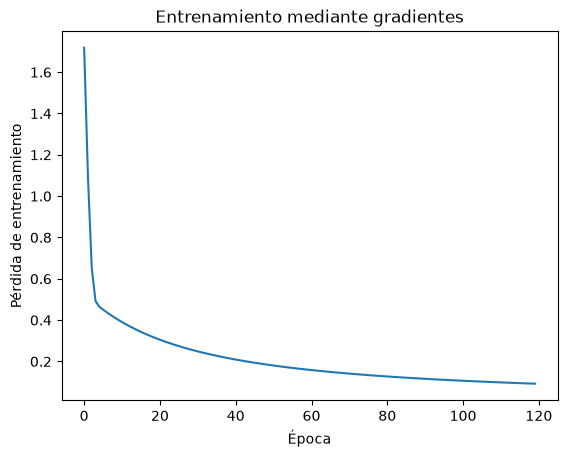

In [53]:
criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)
historial = entrenar_modelo_binario(modelo, X_tensor, y_perdida, criterio, optimizador, epocas=120)

plt.plot(historial)
plt.xlabel('Época')
plt.ylabel('Pérdida de entrenamiento')
plt.title('Entrenamiento mediante gradientes')
plt.show()

**Frontera de decisión.**

Reutilizá el despeje de la recta de separación presentado en la **Actividad 2**.

Con los pesos y el sesgo que ya proporciona la celda siguiente, completá únicamente el código delimitado por las líneas punteadas para graficar esa recta junto con los datos de *Iris setosa* y *Iris versicolor*.

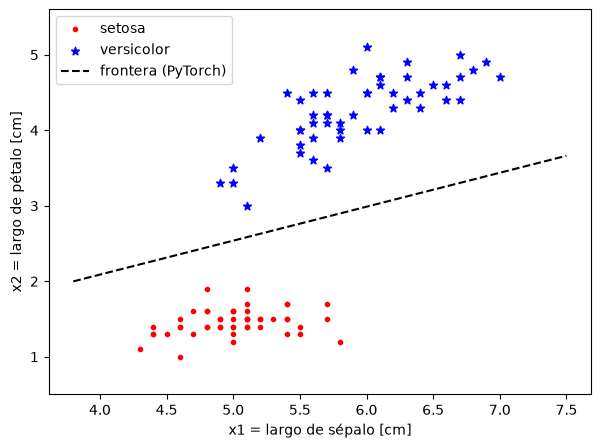

In [54]:
# Obtener los pesos y el sesgo de la neurona entrenada
pesos = modelo.lineal.weight.detach().numpy()[0]   # [w1, w2]
w0 = modelo.lineal.bias.detach().item()            # sesgo

#----------------------------------------------------------------
w1, w2 = pesos  # separo los dos pesos de las entradas

# La frontera es donde el logit vale 0 (sigmoide(0) = 0.5, la neurona "duda"):
#   w1*x1 + w2*x2 + w0 = 0   ->   x2 = -(w1/w2)*x1 - w0/w2
m = -w1 / w2   # pendiente
b = -w0 / w2   # ordenada al origen

x1_rango = np.linspace(X_np[:, 0].min() - 0.5, X_np[:, 0].max() + 0.5, 100)
x2_frontera = m * x1_rango + b

plt.figure(figsize=(7, 5))
plt.scatter(X_np[:50, 0], X_np[:50, 1], color="red", marker=".", label="setosa")
plt.scatter(X_np[50:, 0], X_np[50:, 1], color="blue", marker="*", label="versicolor")
plt.plot(x1_rango, x2_frontera, "k--", label="frontera (PyTorch)")
plt.ylim(X_np[:, 1].min() - 0.5, X_np[:, 1].max() + 0.5)
plt.xlabel("x1 = largo de sépalo [cm]")
plt.ylabel("x2 = largo de pétalo [cm]")
plt.legend()
plt.show()
# ----------------------------------------------------------------

**Análisis — pérdida y frontera.**

- **Tendencia:** la pérdida cae muy rápido en las primeras ~5 épocas (de ~1,7 a ~0,5) y después sigue bajando más despacio hasta ~0,09 a las 120 épocas, sin haberse estabilizado del todo.
- **¿Es necesariamente decreciente en todas las épocas?** No. Acá lo es porque se usa todo el conjunto en cada paso (descenso por gradiente de lote completo) con una tasa moderada. Con una tasa demasiado grande el paso puede pasarse del mínimo y la pérdida subir en algunas épocas, y con minilotes la curva es ruidosa.
- **Frontera:** la recta (pendiente ≈ 0,45) separa las dos especies sin errores. Es parecida a la del perceptrón, pero queda más centrada entre las nubes de puntos: el perceptrón se detiene apenas deja de equivocarse (y su recta pasa más cerca de setosa), mientras que la entropía cruzada sigue disminuyendo al aumentar la confianza en la clasificación.

**Experimentación con la tasa de aprendizaje.**

Ejecutá el bloque siguiente para entrenar dos neuronas nuevas, una con `lr=0.01` y otra con `lr=0.1`. Compará sus curvas de pérdida. ¿Cuál disminuye más rápidamente en las primeras épocas? ¿Se puede concluir que una tasa de aprendizaje mayor siempre es mejor?

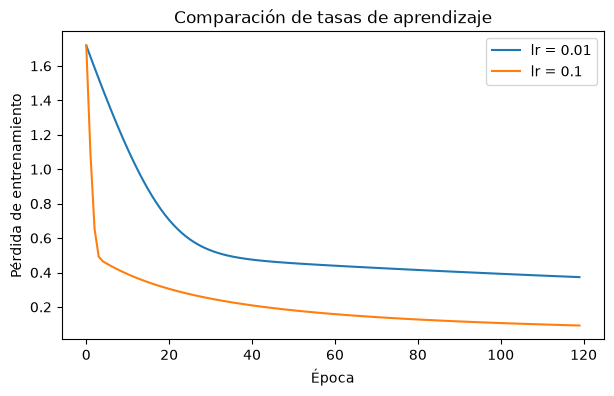

In [55]:
# Comparación de dos tasas de aprendizaje usando la misma inicialización.
plt.figure(figsize=(7, 4))

for tasa_aprendizaje in [0.01, 0.1]:
    torch.manual_seed(42)
    modelo_comparacion = NeuronaBinaria()
    criterio_comparacion = nn.BCEWithLogitsLoss()
    optimizador_comparacion = torch.optim.SGD(
        modelo_comparacion.parameters(), lr=tasa_aprendizaje
    )

    historial_comparacion = entrenar_modelo_binario(
        modelo_comparacion, X_tensor, y_perdida,
        criterio_comparacion, optimizador_comparacion, epocas=120
    )
    plt.plot(historial_comparacion, label=f"lr = {tasa_aprendizaje}")

plt.xlabel("Época")
plt.ylabel("Pérdida de entrenamiento")
plt.title("Comparación de tasas de aprendizaje")
plt.legend()
plt.show()

**Análisis — comparación de tasas de aprendizaje.**

- **¿Cuál disminuye más rápido?** `lr = 0,1`: en pocas épocas ya está en ~0,5, mientras que `lr = 0,01` tarda ~35-40 épocas en llegar a ese valor. A las 120 épocas, la pérdida es ~0,09 con `lr = 0,1` y ~0,37 con `lr = 0,01`.
- **¿Una tasa mayor es siempre mejor?** No. Una tasa grande puede hacer que el paso se pase del mínimo, que la pérdida oscile o incluso que el entrenamiento diverja; una muy chica es estable pero lenta. La mejor tasa depende del problema, de la escala de los datos y del optimizador. Que `0,1` funcione bien acá no garantiza que funcione en otros casos.

### 3. Perceptrón multicapa y problema XOR

En las actividades anteriores clasificamos datos mediante modelos con una única neurona y una frontera de decisión lineal.

Ahora utilizaremos **XOR** (*OR exclusivo*), cuya salida es 1 cuando las dos entradas son diferentes y 0 cuando son iguales.

| $x_1$ | $x_2$ | XOR |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Las dos clases **no son linealmente separables**: ninguna recta puede separar correctamente los cuatro patrones.

El archivo `datos_xor_binario.mat` contiene 80 ejemplos con dos características y etiquetas 0/1 para explorar este problema.

Para resolver XOR utilizaremos un **perceptrón multicapa 2–2–1**: dos entradas, dos neuronas en la capa oculta con activación `Tanh` y una salida lineal (**logit**).

Seguiremos usando `BCEWithLogitsLoss` y la función de entrenamiento de la Actividad 3.

**Exploración:** ejecutá la celda siguiente, observá que los patrones no se pueden separar mediante una única recta.

Forma de las entradas: torch.Size([80, 2])
Forma de las etiquetas: torch.Size([80, 1])
Clases: tensor([0., 1.])


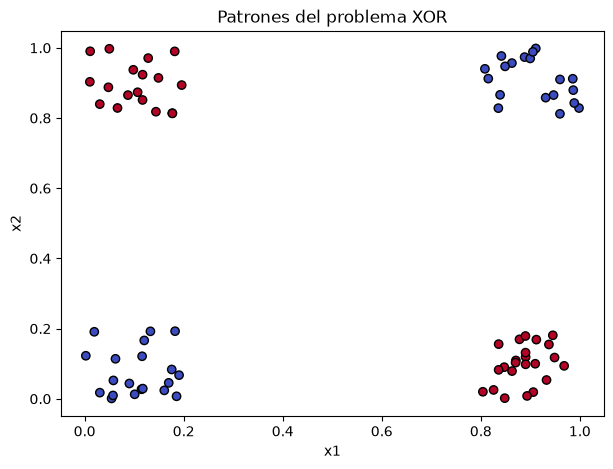

In [56]:
from scipy.io import loadmat

# Cargar los patrones desde el archivo externo.
datos_xor = loadmat("./datos_xor_binario.mat")
X_xor = torch.tensor(datos_xor["X"], dtype=torch.float32)
y_xor = torch.tensor(datos_xor["Y"].reshape(-1, 1), dtype=torch.float32)

print("Forma de las entradas:", X_xor.shape)
print("Forma de las etiquetas:", y_xor.shape)
print("Clases:", torch.unique(y_xor))

plt.figure(figsize=(7, 5))
plt.scatter(X_xor[:, 0], X_xor[:, 1],
            c=y_xor[:, 0], cmap="coolwarm", edgecolor="k")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Patrones del problema XOR")
plt.show()

**Exploración.** Los 80 patrones forman cuatro nubes alrededor de las esquinas de un cuadrado, y las dos clases ocupan esquinas opuestas (en diagonal). Ninguna recta deja una clase de cada lado: los datos no son linealmente separables, por eso una sola neurona no alcanza.

### Actividad 4 — Perceptrón multicapa para XOR

**Parte A. Arquitectura.**

Identificá las dos capas `nn.Linear`, la función `Tanh` y la salida del modelo.  

In [57]:
class RedXOR(nn.Module):
    def __init__(self, neuronas_ocultas=2):
        super().__init__()
        self.capa_oculta = nn.Linear(2, neuronas_ocultas)   # Capa 1: 2 entradas -> 2 neuronas ocultas (W1: 2x2, b1: 2)
        self.activacion = nn.Tanh()    # No linealidad de la capa oculta (salida entre -1 y 1)
        self.capa_salida = nn.Linear(neuronas_ocultas, 1)   # Capa 2: 2 ocultas -> 1 salida (W2: 2x1, b2: 1)

    def forward(self, x):
        z1 = self.capa_oculta(x)    # z1 = x·W1 + b1  (suma ponderada de la capa oculta)
        h = self.activacion(z1)     # h = tanh(z1)    (activación de la capa oculta)
        z2 = self.capa_salida(h)    # z2 = h·W2 + b2  (LOGIT; no se aplica sigmoide acá)
        return z2

**Conclusiones:**
- **Capas `nn.Linear`:** `capa_oculta` (2 entradas → 2 neuronas) y `capa_salida` (2 neuronas ocultas → 1 salida).
- **Función `Tanh`:** `activacion`, aplicada a la salida de la capa oculta.
- **Salida del modelo:** el logit `z2` (sin sigmoide; la sigmoide la aplican `BCEWithLogitsLoss` al entrenar y `predecir()` al predecir).
- Son $(2\cdot2+2)+(2\cdot1+1)=9$ parámetros.
- **Por qué hace falta la capa oculta con `Tanh`:** sin la no linealidad, dos capas lineales seguidas equivalen a una sola capa lineal y solo podrían trazar una recta, que no separa XOR.

**Parte B. Entrenamiento con SGD.**

Entrená el modelo reutilizando `entrenar_modelo_binario()`, como en la Actividad 3.

Luego, **graficá la pérdida de entrenamiento en función de las épocas** utilizando el historial devuelto por esa función. Observá si la pérdida disminuye y cómo evoluciona durante el entrenamiento.

In [58]:
torch.manual_seed(7)
# ---------------------------------------------------------------------
modelo_xor = RedXOR(neuronas_ocultas=2)  # Red 2-2-1, inicializada con la semilla 7
criterio_xor = nn.BCEWithLogitsLoss()    # Sigmoide + entropía cruzada binaria (etiquetas 0/1)
optimizador_sgd = torch.optim.SGD(modelo_xor.parameters(), lr=0.1)

# reutilizamos la función de entrenamiento 
historial_sgd = entrenar_modelo_binario(modelo_xor, X_xor, y_xor,
                                        criterio_xor, optimizador_sgd, epocas=2000)
#---------------------------------------------------------------------

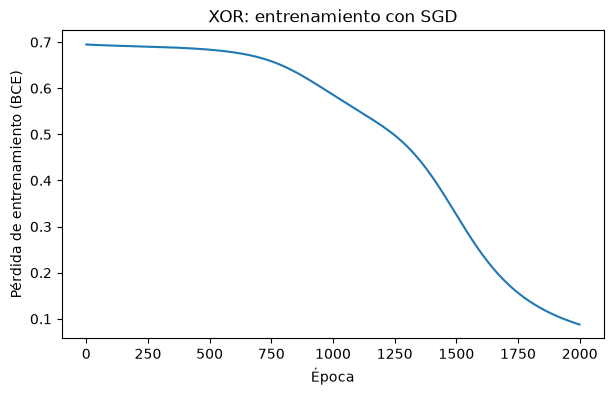

In [59]:
# ----------------------------------------------------------------------
# curva de pérdida
plt.figure(figsize=(7, 4))
plt.plot(historial_sgd)
plt.xlabel("Época")
plt.ylabel("Pérdida de entrenamiento (BCE)")
plt.title("XOR: entrenamiento con SGD")
plt.show()
# ---------------------------------------------------------------------

**Predicciones del modelo.**

Utilizá la función `predecir()` que se proporciona a continuación y ejecutá el ejemplo para evaluar el modelo entrenado con SGD sobre los patrones XOR. La función transforma los logits en probabilidades mediante `torch.sigmoid()` y asigna las clases 0/1 con un umbral de 0,5.

Observá la exactitud obtenida. Esta corresponde a los **datos de entrenamiento** y nos permitirá comparar luego el resultado con Adam.

In [60]:
def predecir(modelo, X):
    modelo.eval()

    with torch.no_grad():
        # Obtener los logits de la red
        logits = modelo(X)

        # Convertir los logits en probabilidades
        probabilidades = torch.sigmoid(logits)

        # Asignar la clase según el umbral de 0.5
        predicciones = torch.where(probabilidades >= 0.5, 1, 0)

    return predicciones, probabilidades

In [61]:
predicciones, probabilidades = predecir(modelo_xor, X_xor)

exactitud = (predicciones == y_xor).float().mean().item()

print(f"Exactitud de entrenamiento: {exactitud*100}%")

Exactitud de entrenamiento: 100.0%


**Conclusiones:**

La pérdida arranca en ~0,69 (≈ ln 2: la red da probabilidad cercana a 0,5 para todo) y casi no cambia durante las primeras ~700 épocas. Después empieza a bajar de forma sostenida y llega a ~0,09 a las 2000 épocas, todavía descendiendo. La exactitud de entrenamiento es **100 %**. Esa exactitud es sobre los datos de entrenamiento, así que no mide la generalización.

**Parte C. Comparación con Adam.**

Adam es otro optimizador basado en gradientes. Para comparar su comportamiento con SGD, **creá y entrená un nuevo modelo `RedXOR`**, con la misma arquitectura y los mismos datos. Utilizá la misma semilla de inicialización y cantidad de épocas que en la Parte B, pero cambiá el optimizador por Adam:

```python
optimizador_adam = torch.optim.Adam(modelo_adam.parameters(), lr=0.01)
```

**Graficá ambas curvas de pérdida en una misma figura**, utilizando los historiales de SGD y Adam, e interpretá las diferencias observadas.

Finalmente, **volvé a utilizar la función `predecir()` proporcionada anteriormente**, esta vez con `modelo_adam`. Calculá la exactitud de entrenamiento y comparala con la obtenida mediante SGD. ¿Qué diferencias observás en la evolución de la pérdida y en las predicciones?

La tasa de aprendizaje no tiene por qué ser igual para ambos optimizadores; una comparación entre estas configuraciones no permite concluir que uno sea siempre superior al otro.

In [62]:
# Entrenar desde la misma inicialización para comparar SGD y Adam.
torch.manual_seed(7)
# ------------------------------------------------------------------------------
modelo_adam = RedXOR(neuronas_ocultas=2)  
criterio_adam = nn.BCEWithLogitsLoss()
optimizador_adam = torch.optim.Adam(modelo_adam.parameters(), lr=0.01)  # Adam: tasa de aprendizaje adaptativa por parámetro

historial_adam = entrenar_modelo_binario(modelo_adam, X_xor, y_xor,
                                         criterio_adam, optimizador_adam, epocas=2000)  # Mismas épocas que SGD
# ------------------------------------------------------------------------------

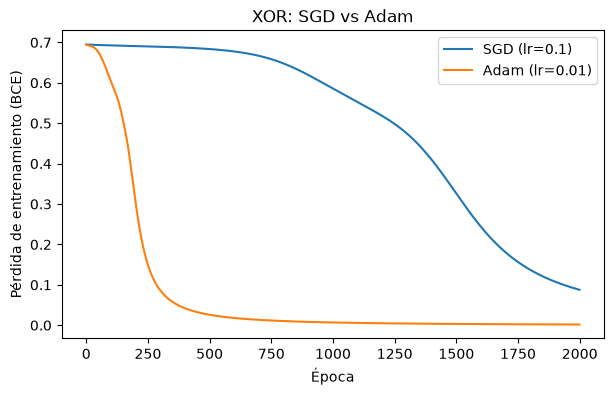

Exactitud de entrenamiento con Adam: 100.0%


In [63]:
# ---------------------------------------------------------------
# ambas curvas en una misma figura + exactitud
plt.figure(figsize=(7, 4))
plt.plot(historial_sgd, label="SGD (lr=0.1)")
plt.plot(historial_adam, label="Adam (lr=0.01)")
plt.xlabel("Época")
plt.ylabel("Pérdida de entrenamiento (BCE)")
plt.title("XOR: SGD vs Adam")
plt.legend()
plt.show()

pred_adam, prob_adam = predecir(modelo_adam, X_xor)   # Logits -> sigmoide -> umbral 0.5
exactitud_adam = (pred_adam == y_xor).float().mean().item()
print(f"Exactitud de entrenamiento con Adam: {exactitud_adam*100}%")
#-------------------------------------------------------------

**Conclusiones:**
- **Evolución de la pérdida:** con Adam ($lr=0{,}01$) la pérdida cae mucho antes: el descenso fuerte ocurre entre las épocas ~100 y ~250, llega a ~0,1 hacia la época 300 y termina en ~0,002. Con SGD ($lr=0{,}1$) hay una meseta larga de ~700 épocas y a las 2000 la pérdida es ~0,09.
- **Predicciones:** ambos modelos alcanzan **100 %** de exactitud de entrenamiento. La exactitud solo mide si la probabilidad queda de un lado u otro de 0,5; la pérdida, en cambio, mide además qué tan segura es la red, y por eso difieren tanto.
- **Interpretación:** con pesos iniciales chicos los gradientes son pequeños y SGD avanza despacio. Adam ajusta el paso de cada parámetro según el tamaño reciente de sus gradientes, así que sale de la meseta antes.
- **Limitación:** las tasas son distintas (0,1 y 0,01), se usó una sola semilla y los datos son de entrenamiento. Por eso no se puede concluir que Adam sea siempre superior; SGD con más épocas o con otra tasa podría llegar a una pérdida similar.

### 4. Redes convolucionales: diseño antes de entrenar

Para convoluciones 2D estándar, la dimensión de salida de cada eje es

$$O=\left\lfloor\frac{W-F+2P}{S}\right\rfloor+1.$$

Las dimensiones **alto y ancho** se calculan por separado si difieren. En pooling se puede aplicar una fórmula análoga usando los parámetros de esa operación.

In [64]:
# W: tamaño de la entrada (ancho y alto)
# F: tamaño del filtro (kernel)
# P: padding
# S: stride
casos = [(28, 3, 0, 1), (28, 3, 1, 1), (28, 3, 1, 2), (14, 2, 0, 2)]

for W, F, P, S in casos:
    tamano_calculado = (W - F + 2 * P) // S + 1

    convolucion = nn.Conv2d(1, 4, kernel_size=F, padding=P, stride=S)
    print("Dimensiones de la capa de convolución:", convolucion.weight.shape)

    # En PyTorch, las entradas para nn.Conv2d tienen el formato: (N, C, H, W)
    # donde N es el tamaño del lote, C es el número de canales, H es la altura y W es el ancho.
    entrada = torch.zeros(1, 1, W, W)  # (N=1, C=1, H=W, W=W)

    salida = convolucion(entrada)

    forma_obtenida = salida.shape

    print(f'W={W}, F={F}, P={P}, S={S}: calculado={tamano_calculado}, obtenido={tuple(forma_obtenida)}\n')

Dimensiones de la capa de convolución: torch.Size([4, 1, 3, 3])
W=28, F=3, P=0, S=1: calculado=26, obtenido=(1, 4, 26, 26)

Dimensiones de la capa de convolución: torch.Size([4, 1, 3, 3])
W=28, F=3, P=1, S=1: calculado=28, obtenido=(1, 4, 28, 28)

Dimensiones de la capa de convolución: torch.Size([4, 1, 3, 3])
W=28, F=3, P=1, S=2: calculado=14, obtenido=(1, 4, 14, 14)

Dimensiones de la capa de convolución: torch.Size([4, 1, 2, 2])
W=14, F=2, P=0, S=2: calculado=7, obtenido=(1, 4, 7, 7)



### Actividad 5 — Diseñar una CNN para MNIST

**¿Qué es MNIST?** Es un conjunto de imágenes de dígitos manuscritos (del **0 al 9**) en escala de grises. Cada imagen tiene un canal y dimensiones de **28 × 28 píxeles**, por lo que la entrada de una imagen se representa como **(1, 28, 28)** en PyTorch.

Se trata de un problema de **clasificación multiclase**: para cada imagen queremos predecir **una de las diez clases posibles**. Por eso, la red deberá producir **10 logits**, uno por clase.

Durante el entrenamiento usaremos `nn.CrossEntropyLoss()`, que recibe esos logits y las etiquetas enteras de 0 a 9; **no agregar Softmax al método `forward()`**.

**Diseño de la arquitectura (antes de programar).** Proponé una CNN siguiendo estas condiciones:

- Dos bloques de **convolución + ReLU + Max-Pooling**. Utilizá kernels de **3 × 3**, `stride=1` y `padding=0` en las convoluciones; para pooling, ventana **2 × 2** y `stride=2`.
- Elegí y justificá el **número de filtros de cada convolución**. Para mantener una práctica manejable, podés usar **4 u 8 filtros en la primera capa**, y **8 o 16 en la segunda**.
- Después de los bloques convolucionales, utilizá `Flatten`, **una capa densa oculta de 32 neuronas con ReLU** y una capa final de **10 salidas**.

**Entregá primero un esquema o tabla** con el orden de las capas y las dimensiones de salida `(C, H, W)` después de cada bloque. Calculá el tamaño del vector que genera `Flatten` y el valor de `in_features` (características de entrada) de la primera capa densa. Finalmente, implementá la arquitectura en la clase `RedCNN` y completá `forward()`.

La combinación exacta de filtros elegida puede variar entre grupos. Lo importante es que las dimensiones sean consistentes y que el modelo termine con diez logits.

**Diseño de la CNN (tabla con el orden antes de programar)** Fórmula: $O=\lfloor (W-F+2P)/S\rfloor+1$.

| Paso | Operación | Salida (C, H, W) |
|---|---|---|
| Entrada | imagen MNIST | (1, 28, 28) |
| Conv1 | 8 filtros 3×3, stride 1, padding 0: (28−3)/1+1 = 26 | (8, 26, 26) |
| ReLU | no cambia dimensiones | (8, 26, 26) |
| MaxPool1 | 2×2, stride 2: ⌊(26−2)/2⌋+1 = 13 | (8, 13, 13) |
| Conv2 | 16 filtros 3×3: (13−3)/1+1 = 11 | (16, 11, 11) |
| ReLU | no cambia dimensiones | (16, 11, 11) |
| MaxPool2 | 2×2, stride 2: ⌊(11−2)/2⌋+1 = 5 | (16, 5, 5) |
| Flatten | 16·5·5 | 400 |
| Densa + ReLU | 400 → 32 | 32 |
| Salida | 32 → 10 | 10 logits |

**Tamaño del vector de `Flatten`: 400. `in_features` de la primera capa densa: 400.** Total de parámetros: 14 410 (coincide con el resultado de `sum(p.numel() ...)`).

**Justificación de los filtros:** elegimos 8 filtros en la primera capa y 16 en la segunda. La primera capa detecta patrones simples (bordes, trazos, esquinas), para los que no hacen falta muchos filtros. La segunda combina esos patrones en formas más complejas (curvas, cruces, partes de dígitos) y por eso conviene más variedad. Duplicar los filtros mientras el mapa espacial se achica es una práctica habitual, y 8/16 mantienen el modelo liviano para entrenar en CPU.

In [7]:
class RedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # convolución + ReLU + pooling 
        self.convolucion1 = nn.Conv2d(in_channels=1, out_channels=8,
                                      kernel_size=3, stride=1, padding=0)
        self.activacion1 = nn.ReLU()   # Pone en 0 los valores negativos
        self.pooling1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bloque 2 
        self.convolucion2 = nn.Conv2d(in_channels=8, out_channels=16,
                                      kernel_size=3, stride=1, padding=0)
        self.activacion2 = nn.ReLU()
        self.pooling2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Clasificador
        self.aplanar = nn.Flatten()                        
        self.densa = nn.Linear(16 * 5 * 5, 32)        
        self.activacion_densa = nn.ReLU()
        self.salida = nn.Linear(32, 10)                    

    def forward(self, x):
        # Bloque 1
        x = self.convolucion1(x)
        x = self.activacion1(x)
        x = self.pooling1(x)
        # Bloque 2
        x = self.convolucion2(x)
        x = self.activacion2(x)
        x = self.pooling2(x)
        # Clasificador
        x = self.aplanar(x)
        x = self.densa(x)
        x = self.activacion_densa(x)
        x = self.salida(x) # Se devuelven LOGITS: sin Softmax,
        return x         

In [66]:
# Después de completar RedCNN, prueba el siguiente código.
cnn = RedCNN()
salida_prueba = cnn(torch.zeros(4, 1, 28, 28)) # prueba con un lote de 4 imágenes de 28x28 píxeles y 1 canal (blanco y negro)
print("Dimensión de salida del lote:", tuple(salida_prueba.shape))

Dimensión de salida del lote: (4, 10)


In [67]:
print("Parámetros totales:", sum(p.numel() for p in cnn.parameters()))

Parámetros totales: 14410


### Actividad 6 — Datos de MNIST: entrenamiento, validación y prueba

El conjunto MNIST incluye **60 000 imágenes de entrenamiento** y **10 000 de prueba**.

Para reducir el tiempo de ejecución, trabajaremos con una muestra de las imágenes disponibles para entrenamiento.

Dividiremos esa muestra en dos conjuntos:

- **Entrenamiento (4000 imágenes):** se utiliza para calcular la pérdida y actualizar los parámetros de la CNN.
- **Validación (800 imágenes):** se utiliza para observar el desempeño sobre imágenes que no participaron en la actualización de parámetros.

El **conjunto de prueba (10 000 imágenes)** se mantiene separado y se utilizará para una evaluación final.

En el código siguiente:

- `datasets.MNIST(..., train=True)` carga los 60 000 ejemplos del conjunto de desarrollo original; `train=False` carga el conjunto de prueba.
- `transforms.ToTensor()` convierte cada imagen a tensor y escala sus píxeles al intervalo de 0 a 1.
- `permutation(...)` genera un orden aleatorio reproducible de los índices; `Subset` selecciona los primeros 4000 para entrenamiento y los 800 siguientes para validación.
- `DataLoader` entrega imágenes y etiquetas en **minilotes**. Con `shuffle=True`, el orden de los ejemplos de entrenamiento cambia entre épocas.

**Exploración:** ejecutá la celda, verificá los tamaños de cada conjunto y observá algunas imágenes con sus etiquetas. Identificá qué dimensiones tiene un lote de 64 imágenes.

Entrenamiento: 4000
Validación: 800
Prueba: 10000


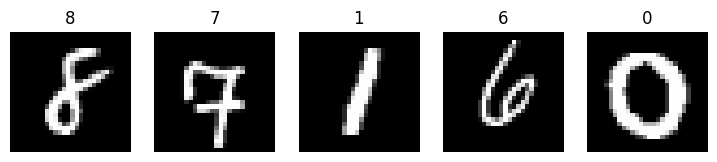

Dimension torch.Size([1, 28, 28])
Dimensiones del lote: torch.Size([64, 1, 28, 28])


In [6]:
# La primera descarga de MNIST requiere conexión a internet.
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

transformacion = transforms.ToTensor()

# MNIST ofrece 60 000 imágenes para entrenamiento y 10 000 para prueba.
datos_completos = datasets.MNIST(root="./data", train=True, download=True, transform=transformacion)
datos_prueba = datasets.MNIST(root="./data", train=False, download=True, transform=transformacion)

# Seleccionar una muestra aleatoria reproducible y dividimos sin repetición.
generador_aleatorio = np.random.default_rng(SEMILLA)
indices = generador_aleatorio.permutation(len(datos_completos))

datos_entrenamiento = Subset(datos_completos, indices[:4000]) #selecciona las primeras 4000 imagenes para entrenamiento
datos_validacion = Subset(datos_completos, indices[4000:4800]) #selecciona las siguiente 800 para validacion

# Crear minilotes. Solo se mezclan los ejemplos durante entrenamiento.
cargador_entrenamiento = DataLoader(datos_entrenamiento, batch_size=64, shuffle=True) #shuffle = True orden cambia por epocas
cargador_validacion = DataLoader(datos_validacion, batch_size=128, shuffle=False)

print("Entrenamiento:", len(datos_entrenamiento))
print("Validación:", len(datos_validacion))
print("Prueba:", len(datos_prueba))

# Mostrar ejemplos del conjunto de entrenamiento.
fig, ejes = plt.subplots(1, 5, figsize=(9, 2))
for eje, indice in zip(ejes, range(5)):
    imagen, etiqueta = datos_entrenamiento[indice]
    eje.imshow(imagen.squeeze(), cmap="gray")
    eje.set_title(str(etiqueta))
    eje.axis("off")
plt.show()

print("Dimension", imagen.shape)
imagenes, _ = next(iter(cargador_entrenamiento))
print("Dimensiones del lote:", imagenes.shape)    # torch.Size([64, 1, 28, 28])

Los tamaños de los conjuntos coinciden con lo esperado: 4000 imágenes de entrenamiento, 800 de validación y 10 000 de prueba. Cada imagen individual tiene dimensión `[1, 28, 28]` (1 canal, por ser escala de grises, y 28×28 píxeles), según lo que muestra `imagen.shape`. Al agruparlas en minilotes, el `DataLoader` agrega una dimensión adicional, por lo que un lote de 64 imágenes tiene dimensión `[64, 1, 28, 28]`. Esto se verifica inspeccionando un lote con `next(iter(cargador_entrenamiento))`.

### Actividad 7 — Entrenamiento convencional de la CNN

**Primero entrenaremos la CNN sin early stopping**, para usar el ciclo de entrenamiento de las actividades anteriores. La diferencia principal es que ahora procesaremos **minilotes** de imágenes y usaremos `CrossEntropyLoss`, porque tenemos diez clases.

En cada minilote se realizan los mismos pasos: limpiar gradientes, calcular los logits, evaluar la pérdida, ejecutar `backward()` y actualizar parámetros mediante `step()`. Una **época** termina cuando se recorrieron todos los minilotes de entrenamiento.

La función siguiente también calcula la pérdida sobre validación al terminar cada época, pero **no usa esos ejemplos para actualizar pesos**.

**Consigna:** una vez completada tu clase `RedCNN`, ejecutá la siguiente función de entrenamiento. Graficá las pérdidas de entrenamiento y validación y compará su evolución. ¿Ambas disminuyen necesariamente del mismo modo?

In [8]:
def entrenar_cnn(modelo, loader_entrenamiento, loader_validacion,
                 criterio, optimizador, epocas=30):

    historial = {"entrenamiento": [], "validacion": []}
    n_entrenamiento = len(loader_entrenamiento.dataset)
    n_validacion = len(loader_validacion.dataset)

    for epoca in range(epocas):

        modelo.train()
        perdida_entrenamiento = 0.0

        # Entrenamiento: actualizar los parámetros con cada minilote.
        for imagenes, etiquetas in loader_entrenamiento:
            optimizador.zero_grad()
            logits = modelo(imagenes)
            perdida = criterio(logits, etiquetas)
            perdida.backward()
            optimizador.step()

            perdida_entrenamiento += perdida.item() * len(imagenes)/n_entrenamiento

        # Validación: calcular la pérdida sin actualizar parámetros.
        modelo.eval()
        perdida_validacion = 0.0

        with torch.no_grad():
            for imagenes, etiquetas in loader_validacion:
                logits = modelo(imagenes)
                perdida = criterio(logits, etiquetas)
                perdida_validacion += perdida.item() * len(imagenes)/n_validacion

        historial["entrenamiento"].append(perdida_entrenamiento)
        historial["validacion"].append(perdida_validacion)
        print(f"Época {epoca + 1:02d}: "
              f"entrenamiento={perdida_entrenamiento:.4f} | "
              f"validación={perdida_validacion:.4f}")

    return historial

Época 01: entrenamiento=1.9025 | validación=1.0177
Época 02: entrenamiento=0.6450 | validación=0.4985
Época 03: entrenamiento=0.4016 | validación=0.3811
Época 04: entrenamiento=0.3208 | validación=0.3099
Época 05: entrenamiento=0.2766 | validación=0.2817
Época 06: entrenamiento=0.2309 | validación=0.2404
Época 07: entrenamiento=0.2066 | validación=0.2280
Época 08: entrenamiento=0.1933 | validación=0.2326
Época 09: entrenamiento=0.1753 | validación=0.2079
Época 10: entrenamiento=0.1558 | validación=0.1900
Época 11: entrenamiento=0.1393 | validación=0.1952
Época 12: entrenamiento=0.1326 | validación=0.1809
Época 13: entrenamiento=0.1225 | validación=0.1764
Época 14: entrenamiento=0.1153 | validación=0.1746
Época 15: entrenamiento=0.1019 | validación=0.1633
Época 16: entrenamiento=0.0906 | validación=0.1746
Época 17: entrenamiento=0.0858 | validación=0.1551
Época 18: entrenamiento=0.0740 | validación=0.1471
Época 19: entrenamiento=0.0657 | validación=0.1541
Época 20: entrenamiento=0.0660 

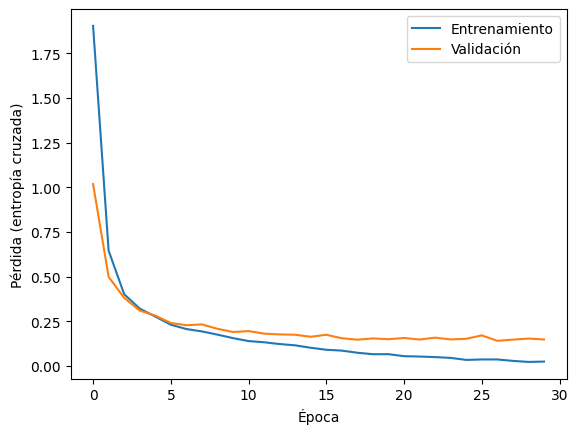

In [9]:
# Ejecutá este bloque después de completar y comprobar RedCNN.
torch.manual_seed(SEMILLA)

cnn = RedCNN()
criterio_cnn = nn.CrossEntropyLoss()
optimizador_cnn = torch.optim.Adam(cnn.parameters(), lr=0.001)

historial_cnn = entrenar_cnn(cnn, cargador_entrenamiento, cargador_validacion,
    criterio_cnn, optimizador_cnn, epocas=30)

plt.plot(historial_cnn["entrenamiento"], label="Entrenamiento")
plt.plot(historial_cnn["validacion"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (entropía cruzada)")
plt.legend()
plt.show()

Las pérdidas de entrenamiento y validación no parten del mismo valor, en la primera época el entrenamiento ronda en 1,90 y la validación 1,02. Esto se explica porque la pérdida de entrenamiento es el promedio de todos los minilotes de la época, incluyendo los primeros, cuando los parámetros todavía están casi sin ajustar, mientras que la de validación se calcula al final de la época, con el modelo ya actualizado. Ambas curvas descienden rápidamente hasta aproximadamente la época 4, donde se cruzan y toman valores casi iguales (≈0,28).

A partir de ese punto las curvas se separan. La pérdida de entrenamiento sigue bajando de forma sostenida hasta aproximadamente 0,02, mientras que la de validación se estabiliza alrededor de 0,15, con pequeñas oscilaciones y sin mejorar de manera apreciable. 

Por lo tanto, ambas pérdidas no disminuyen necesariamente del mismo modo. El modelo continúa ajustándose a las imágenes de entrenamiento, pero esa mejora ya no se observa en las imágenes de validación. La brecha creciente entre ambas curvas indica un comienzo de sobreajuste, y es por eso el uso de early stopping en la actividad siguiente.

### Actividad 8 — *Early Stopping*

En la actividad anterior entrenamos la CNN durante una cantidad fija de épocas. Sin embargo, observamos que la pérdida de entrenamiento puede continuar disminuyendo aun cuando la pérdida de validación deja de mejorar.

Esto plantea una pregunta: ¿cómo podemos determinar automáticamente cuándo conviene detener el entrenamiento?

Una estrategia es utilizar *early stopping*, que monitorea la pérdida de validación y detiene el entrenamiento cuando no se observan mejoras durante una cantidad determinada de épocas consecutivas.

El parámetro `paciencia` (*patience*) establece cuántas épocas sin mejora se toleran antes de detener el entrenamiento.

**Consigna**: utilizá la siguiente función de entrenamiento con early stopping y compará sus resultados con el entrenamiento convencional.

Analizá en qué época se obtiene la menor pérdida de validación, cuándo se detiene el entrenamiento y por qué resulta conveniente recuperar los parámetros correspondientes al mejor resultado de validación.
Compará las curvas y la cantidad de épocas con ambos entrenamientos.

In [10]:
import copy

def entrenar_cnn_con_early_stopping(modelo, cargador_entrenamiento, cargador_validacion, criterio, optimizador,
                                   max_epocas=30, paciencia=3):

    n_entrenamiento = len(cargador_entrenamiento.dataset)
    n_validacion = len(cargador_validacion.dataset)
    mejor_validacion = float("inf")
    mejor_epoca = 0
    mejores_pesos = copy.deepcopy(modelo.state_dict())
    sin_mejora = 0
    historial = {"entrenamiento": [], "validacion": []}

    for epoca in range(max_epocas):
        modelo.train()
        perdida_entrenamiento = 0.0

        for imagenes, etiquetas in cargador_entrenamiento:
            optimizador.zero_grad()
            logits = modelo(imagenes)
            perdida = criterio(logits, etiquetas)
            perdida.backward()
            optimizador.step()

            # Promedio ponderado por la cantidad de imágenes del minilote.
            perdida_entrenamiento += perdida.item() * len(imagenes) / n_entrenamiento

        modelo.eval()
        perdida_validacion = 0.0
        with torch.no_grad():
            for imagenes, etiquetas in cargador_validacion:
                logits = modelo(imagenes)
                perdida = criterio(logits, etiquetas)
                perdida_validacion += perdida.item() * len(imagenes) / n_validacion

        historial["entrenamiento"].append(perdida_entrenamiento)
        historial["validacion"].append(perdida_validacion)
        print(f"Época {epoca + 1:02d}: "
              f"entrenamiento={perdida_entrenamiento:.4f} | "
              f"validación={perdida_validacion:.4f}")

        if perdida_validacion < mejor_validacion:
            mejor_validacion = perdida_validacion
            mejor_epoca = epoca + 1
            mejores_pesos = copy.deepcopy(modelo.state_dict())
            sin_mejora = 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                print("Se activa early stopping.")
                break

    # Recuperar los parámetros de la época con menor pérdida de validación.
    modelo.load_state_dict(mejores_pesos)
    print(f"Mejor época: {mejor_epoca}")
    print(f"Menor pérdida de validación: {mejor_validacion:.4f}")
    return historial

Época 01: entrenamiento=1.9025 | validación=1.0177
Época 02: entrenamiento=0.6450 | validación=0.4985
Época 03: entrenamiento=0.4016 | validación=0.3811
Época 04: entrenamiento=0.3208 | validación=0.3099
Época 05: entrenamiento=0.2766 | validación=0.2817
Época 06: entrenamiento=0.2309 | validación=0.2404
Época 07: entrenamiento=0.2066 | validación=0.2280
Época 08: entrenamiento=0.1933 | validación=0.2326
Época 09: entrenamiento=0.1753 | validación=0.2079
Época 10: entrenamiento=0.1558 | validación=0.1900
Época 11: entrenamiento=0.1393 | validación=0.1952
Época 12: entrenamiento=0.1326 | validación=0.1809
Época 13: entrenamiento=0.1225 | validación=0.1764
Época 14: entrenamiento=0.1153 | validación=0.1746
Época 15: entrenamiento=0.1019 | validación=0.1633
Época 16: entrenamiento=0.0906 | validación=0.1746
Época 17: entrenamiento=0.0858 | validación=0.1551
Época 18: entrenamiento=0.0740 | validación=0.1471
Época 19: entrenamiento=0.0657 | validación=0.1541
Época 20: entrenamiento=0.0660 

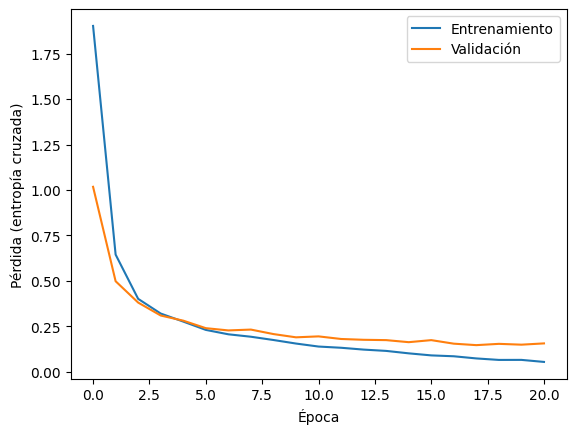

In [11]:
# Crear una instancia nueva para comparar entrenamientos.
torch.manual_seed(SEMILLA)
cnn_early_stopping = RedCNN()
criterio_early_stopping = nn.CrossEntropyLoss()
optimizador_early_stopping = torch.optim.Adam(cnn_early_stopping.parameters(), lr=0.001)

historial_early_stopping = entrenar_cnn_con_early_stopping(
    cnn_early_stopping, cargador_entrenamiento, cargador_validacion,
    criterio_early_stopping, optimizador_early_stopping,
    max_epocas=30, paciencia=3
)
plt.plot(historial_early_stopping["entrenamiento"], label="Entrenamiento")
plt.plot(historial_early_stopping["validacion"], label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida (entropía cruzada)")
plt.legend()
plt.show()

Al comparar con el entrenamiento convencional, las primeras épocas son prácticamente iguales, ambas curvas descienden rápido y se cruzan en la época 4, con una pérdida cercana a 0,28. Esto es esperable, porque el early stopping no modifica cómo se entrena el modelo, sino que decide cuándo detenerlo.

En el **entrenamiento con *early stopping***, la menor pérdida de validación se obtiene en la época 18 (0,1471). Después de esa época la validación no volvió a mejorar durante tres épocas consecutivas, por lo que el entrenamiento se detuvo en la época 21. Resulta conveniente recuperar los parámetros de la época 18 porque son los que mejor desempeño tuvieron sobre datos no usados para actualizar pesos.

En el **entrenamiento sin early stopping** se completaron las 30 épocas y la pérdida de entrenamiento continuó bajando (≈0,03) mientras que la de validación se mantuvo estable alrededor de 0,15 con oscilaciones, de modo que la brecha entre ambas siguió ampliándose. **Con *early stopping*** el entrenamiento se detuvo en 21 épocas, con una pérdida de entrenamiento de 0,0547 y una de validación de aproximadamente 0,15, por lo que la brecha es menor. Además, la validación alcanzó un valor similar en ambos casos, pero con early stopping se obtuvo con menos épocas y, por lo tanto, menos costo computacional.

### Evaluación final y preguntas de cierre

Al finalizar el entrenamiento, calculá la **exactitud de clasificación**. Evaluá primero sobre validación y, una vez finalizadas las decisiones de diseño y entrenamiento, sobre el conjunto de prueba.

In [12]:
def evaluar_exactitud(modelo, cargador):
    modelo.eval()
    aciertos = 0
    cantidad_total = 0
    with torch.no_grad():
        for imagenes, etiquetas in cargador:
            logits = modelo(imagenes)
            probabilidades = torch.softmax(logits, dim=1)
            predicciones = probabilidades.argmax(dim=1)
            aciertos += (predicciones == etiquetas).sum().item()
            cantidad_total += len(etiquetas)
    return aciertos / cantidad_total


# Ejecutá después del entrenamiento convencional.
print(f"Exactitud de validación: {evaluar_exactitud(cnn, cargador_validacion):.2%}")

# Solo para la evaluación final:
cargador_prueba = DataLoader(datos_prueba, batch_size=256, shuffle=False)
print(f"Exactitud de prueba: {evaluar_exactitud(cnn, cargador_prueba):.2%}")

Exactitud de validación: 96.88%
Exactitud de prueba: 96.69%


Al observar la exactitud en validación (96,88 %) y en prueba (96,69 %), se concluye que el modelo clasifica correctamente casi el 97 % de las imágenes. Ambas exactitudes difieren en aproximadamente 0,2 puntos porcentuales, lo que indica que el modelo generaliza bien las imágenes nuevas y que el sobreajuste observado en las curvas de pérdida no afectó de forma significativa el desempeño final.

Cabe considerar que la exactitud de prueba es la estimación más confiable del desempeño sobre datos nuevos, ya que ese conjunto no participó en ninguna decisión de diseño ni de entrenamiento, a diferencia de la validación, que se usó, por ejemplo, para elegir la época de parada. Además, que ambos valores sean tan cercanos sugiere que esas decisiones no sobreajustaron al conjunto de validación.